# PDO Cell Painting pipeline figure

A publication-style schematic drawn entirely from matplotlib polygons:

1. **Patient tumor resection, organoid culture & drug treatment** (one continuous process):
   patient → resected tumors of several types → dissociation into single cells → plating in a 96-well
   plate → one well magnified (Matrigel ring, top and side views) → assay timeline (Day 0 seeding,
   Days 1–3 organoid formation, Days 4–5 drug treatment, Day 6 Cell Painting) → arrow to the microscope
2. **Cell Painting + high-content volumetric imaging**: AGP, DNA, ER and Mito z-stacks
3. **2.5D/3D segmentation**: nuclei, cells, cytoplasm and whole-organoid masks

The figure is sized for a 180 mm double-column journal width with 6–9 pt text, and is exported as
vector PDF/SVG (editable text) plus a 600 dpi PNG.

The mini-ring assay format and timeline in panel 1 follow Phan *et al.*, *Commun. Biol.* **2**, 78 (2019);
cite that paper if you use this panel.

**Requires:** `numpy`, `matplotlib`, `scipy`

> The micrographs are synthetic. To use real data, replace the arrays returned by
> `channel_images()` with your own 2D max-projections scaled to 0–1 (see the note in that section).

In [1]:
import pathlib

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Polygon, RegularPolygon
from notebook_init_utils.notebook_init_utils import init_notebook
from scipy.ndimage import gaussian_filter
from scipy.spatial import Voronoi

root_dir, in_notebook = init_notebook()

In [ ]:
output_figure_file_path = pathlib.Path(
    f"{root_dir}/figures/workflow_figures/figures/pdo_pipeline_figure"
)
output_figure_file_path.parent.mkdir(parents=True, exist_ok=True)

## Settings
Fonts fall back from Arial → Helvetica → Liberation Sans → DejaVu Sans, depending on what is installed.
`rng` fixes the random organoid layout; change the seed for a different arrangement.
Drawing coordinates are in abstract units on a `W × H` canvas; the figure is scaled to `FIG_W_IN` inches wide.

In [3]:
mpl.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
        "pdf.fonttype": 42,  # editable TrueType text in PDF
        "ps.fonttype": 42,
        "svg.fonttype": "none",  # keep text as text in SVG
    }
)

rng = np.random.default_rng(7)

W, H = 20.0, 8.0  # drawing units
FIG_W_IN = 180 / 25.4  # 180 mm double-column width
INK = "#222222"
GREY = "#6b6b6b"
LIGHT = "#eceef1"
SLATE = "#5b6b82"  # organoids, drug, dose gradient
MATRIGEL = "#e3d9c6"
MEDIUM = "#f6f7f9"
DRUG = "#c9d0db"  # medium containing drug
LW = 0.7  # standard stroke (pt)
SEG_CMAP = plt.get_cmap("cividis")

FS_TITLE, FS_LABEL, FS_SMALL = 9, 7, 6
OUT_STEM = "pdo_pipeline_figure"  # output file name (without extension)

## Polygon helpers
Every shape in the figure is a `Polygon`: bevelled boxes (`chamfer`), circles (`circle`) and arrows (`arrow_poly`).

In [4]:
def chamfer(x, y, w, h, c=0.1):
    """Rectangle with small cut corners."""
    return np.array(
        [
            (x + c, y),
            (x + w - c, y),
            (x + w, y + c),
            (x + w, y + h - c),
            (x + w - c, y + h),
            (x + c, y + h),
            (x, y + h - c),
            (x, y + c),
        ]
    )


def circle(cx, cy, r, n=64):
    t = np.linspace(0, 2 * np.pi, n, endpoint=False)
    return np.c_[cx + r * np.cos(t), cy + r * np.sin(t)]


def poly(ax, verts, fc="none", ec=INK, lw=LW, z=3, closed=True, **kw):
    p = Polygon(
        verts, closed=closed, fc=fc, ec=ec, lw=lw, zorder=z, joinstyle="miter", **kw
    )
    ax.add_patch(p)
    return p


def arrow_poly(p0, p1, w=0.1, hw=0.3, hl=0.26):
    p0, p1 = np.asarray(p0, float), np.asarray(p1, float)
    u = (p1 - p0) / np.linalg.norm(p1 - p0)
    n = np.array([-u[1], u[0]])
    a = p1 - u * hl
    return np.array(
        [
            p0 + n * w / 2,
            a + n * w / 2,
            a + n * hw / 2,
            p1,
            a - n * hw / 2,
            a - n * w / 2,
            p0 - n * w / 2,
        ]
    )


def arrow(ax, p0, p1, color=INK, z=8, **kw):
    poly(ax, arrow_poly(p0, p1, **kw), fc=color, ec="none", z=z)


def bar(ax, p0, p1, w=0.08, color=INK, z=8):
    """Straight polygon segment, extended by w/2 at both ends so joints close cleanly."""
    p0, p1 = np.asarray(p0, float), np.asarray(p1, float)
    u = (p1 - p0) / np.linalg.norm(p1 - p0)
    n = np.array([-u[1], u[0]]) * w / 2
    a, b = p0 - u * w / 2, p1 + u * w / 2
    poly(ax, [a + n, b + n, b - n, a - n], fc=color, ec="none", z=z)


def connector(ax, pts, w=0.08, hw=0.24, hl=0.18, color=INK, z=8):
    """Multi-segment polygon arrow through the points in `pts`."""
    for a, b in zip(pts[:-2], pts[1:-1]):
        bar(ax, a, b, w, color, z)
    arrow(ax, pts[-2], pts[-1], color, z, w=w, hw=hw, hl=hl)


def text(
    ax,
    x,
    y,
    s,
    size=FS_LABEL,
    color=INK,
    weight="normal",
    ha="center",
    va="center",
    **kw,
):
    ax.text(
        x,
        y,
        s,
        fontsize=size,
        color=color,
        weight=weight,
        ha=ha,
        va=va,
        zorder=20,
        linespacing=1.1,
        **kw,
    )

## Organoid geometry
One organoid is generated here and reused in the imaging and segmentation panels so they match:
a wobbly outline (`BLOB`), cell centres (`SEEDS`), Voronoi cell polygons (`CELLS`) and irregular nuclei (`NUCLEI`).
Label colours are sampled from the colourblind-safe **cividis** colormap.

In [5]:
def r_fun(th):
    return 0.72 * (1 + 0.07 * np.sin(3 * th + 0.4) + 0.05 * np.cos(5 * th + 1.1))


def sample_seeds(n=26, min_d=0.17):
    seeds = []
    while len(seeds) < n:
        p = rng.uniform(-0.8, 0.8, 2)
        rho, th = np.hypot(*p), np.arctan2(p[1], p[0])
        if rho < r_fun(th) - 0.07 and all(np.hypot(*(p - q)) > min_d for q in seeds):
            seeds.append(p)
    return np.array(seeds)


SEEDS = sample_seeds()
THETA = np.linspace(0, 2 * np.pi, 220, endpoint=False)
BLOB = np.c_[r_fun(THETA) * np.cos(THETA), r_fun(THETA) * np.sin(THETA)]
LABEL_COLORS = [SEG_CMAP(v) for v in rng.uniform(0.12, 0.95, len(SEEDS))]


def voronoi_polys(seeds):
    far = np.array([[-10, -10], [10, -10], [10, 10], [-10, 10]])
    vor = Voronoi(np.vstack([seeds, far]))
    out = []
    for i in range(len(seeds)):
        v = vor.vertices[vor.regions[vor.point_region[i]]]
        c = v.mean(axis=0)
        out.append(v[np.argsort(np.arctan2(v[:, 1] - c[1], v[:, 0] - c[0]))])
    return out


CELLS = voronoi_polys(SEEDS)


def nucleus_poly(c, k=11):
    a, b = rng.uniform(0.06, 0.085), rng.uniform(0.045, 0.065)
    rot = rng.uniform(0, np.pi)
    t = np.linspace(0, 2 * np.pi, k, endpoint=False)
    rr = 1 + rng.normal(0, 0.08, k)
    x, y = a * rr * np.cos(t), b * rr * np.sin(t)
    return (
        np.c_[x * np.cos(rot) - y * np.sin(rot), x * np.sin(rot) + y * np.cos(rot)] + c
    )


NUCLEI = [nucleus_poly(s) for s in SEEDS]


def to_frame(uv, x, y, s):
    uv = np.asarray(uv)
    return np.c_[x + (uv[:, 0] + 1) / 2 * s, y + (uv[:, 1] + 1) / 2 * s]

## Cell Painting channels
Synthetic grayscale images built from the same geometry: membranes (AGP), nuclei (DNA), perinuclear rings (ER) and punctate signal (Mito).

**To use real images:** replace this function with one that returns a dict
`{"AGP": array, "DNA": array, "ER": array, "Mito": array}` of 2D arrays scaled to 0–1.

In [6]:
def channel_images(n=300):
    g = np.linspace(-1, 1, n)
    uu, vv = np.meshgrid(g, g)
    rho, th = np.hypot(uu, vv), np.arctan2(vv, uu)
    r = r_fun(th)
    inside = 1 / (1 + np.exp(-(r - rho) / 0.015))
    rim = np.exp(-(((rho - r) / 0.03) ** 2))
    d = np.sort(
        np.hypot(
            uu[None] - SEEDS[:, 0, None, None], vv[None] - SEEDS[:, 1, None, None]
        ),
        axis=0,
    )
    d1, d2 = d[0], d[1]
    membrane = np.exp(-(((d2 - d1) / 0.022) ** 2))
    nuc = np.exp(-((d1 / 0.06) ** 4))
    speck = gaussian_filter(rng.random((n, n)), 1.3)
    speck = ((speck - speck.min()) / np.ptp(speck)) ** 5 * 3
    bg = gaussian_filter(rng.random((n, n)), 1) * 0.05
    imgs = {
        "AGP": inside * (0.1 + 0.8 * membrane) + 0.45 * rim,
        "DNA": inside * nuc * (0.7 + 0.3 * gaussian_filter(rng.random((n, n)), 2)),
        "ER": inside * (0.2 + 0.55 * np.exp(-(((d1 - 0.1) / 0.035) ** 2))) + 0.5 * rim,
        "Mito": inside * (1 - nuc) * (0.1 + 0.8 * speck) + 0.2 * rim,
    }
    return {k: np.clip(v + bg, 0, 1) for k, v in imgs.items()}

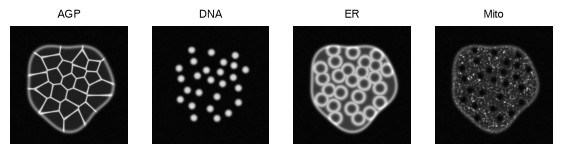

In [7]:
# Quick preview of the four channels
imgs_preview = channel_images()
fig_prev, axes = plt.subplots(1, 4, figsize=(7, 1.9))
for a, (name, img) in zip(axes, imgs_preview.items()):
    a.imshow(img, cmap="gray", origin="lower", vmin=0, vmax=1)
    a.set_title(name, fontsize=8)
    a.axis("off")
plt.show()

## z-stacks and segmentation renderers
`stack` draws a pile of offset slices with content clipped into the front slice.
The `seg_*` functions draw the label maps; `channel_drawer` wraps a channel image for the imaging panel.

In [8]:
def stack(ax, x, y, s, draw_front, n=6, off=0.055, z=10):
    for i in range(n - 1, 0, -1):
        poly(
            ax,
            [
                (x - i * off, y + i * off),
                (x - i * off + s, y + i * off),
                (x - i * off + s, y + i * off + s),
                (x - i * off, y + i * off + s),
            ],
            fc="white",
            ec=GREY,
            lw=0.5,
            z=z,
        )
    clip = poly(
        ax,
        [(x, y), (x + s, y), (x + s, y + s), (x, y + s)],
        fc="black",
        ec=INK,
        lw=0.6,
        z=z + 0.5,
    )
    draw_front(ax, x, y, s, clip, z + 1)


def seg_nuclei(ax, x, y, s, clip, z):
    for pv, c in zip(NUCLEI, LABEL_COLORS):
        p = poly(ax, to_frame(pv, x, y, s), fc=c, ec="none", z=z)
        p.set_clip_path(clip)


def seg_cells(ax, x, y, s, clip, z, cyto=False):
    blob = poly(ax, to_frame(BLOB, x, y, s), fc="none", ec="none", z=z)
    for pv, c in zip(CELLS, LABEL_COLORS):
        p = poly(ax, to_frame(pv, x, y, s), fc=c, ec="black", lw=0.3, z=z)
        p.set_clip_path(blob)
    if cyto:
        for pv in NUCLEI:
            poly(ax, to_frame(pv, x, y, s), fc="black", ec="none", z=z + 0.3)


def seg_organoid(ax, x, y, s, clip, z):
    poly(ax, to_frame(BLOB, x, y, s), fc=SEG_CMAP(0.75), ec="none", z=z)


def channel_drawer(img):
    def draw(ax, x, y, s, clip, z):
        im = ax.imshow(
            img,
            extent=[x, x + s, y, y + s],
            cmap="gray",
            vmin=0,
            vmax=1,
            origin="lower",
            zorder=z,
            interpolation="bilinear",
        )
        im.set_clip_path(clip)

    return draw

## Icons
Outline-style icons for the patient, sample tube, plate, drug and microscope, plus `dissociation`:
a piece of tumor tissue (Voronoi cells clipped to a jagged polygon) broken up into single cells.

In [9]:
def person(ax, cx, cy):
    poly(ax, circle(cx, cy + 0.68, 0.24, 40), fc=LIGHT)
    poly(ax, chamfer(cx - 0.34, cy - 0.38, 0.68, 0.78, 0.18), fc=LIGHT)


def tube(ax, cx, cy, s=1.0, liquid="#b9bec7"):
    P = lambda pts: [(cx + s * dx, cy + s * dy) for dx, dy in pts]
    poly(
        ax,
        P([(-0.16, 0.4), (0.16, 0.4), (0.16, -0.15), (0, -0.52), (-0.16, -0.15)]),
        fc="white",
    )
    poly(
        ax,
        P([(-0.16, -0.02), (0.16, -0.02), (0.16, -0.15), (0, -0.52), (-0.16, -0.15)]),
        fc=liquid,
        ec="none",
        z=3.2,
    )
    poly(
        ax,
        chamfer(cx - 0.21 * s, cy + 0.4 * s, 0.42 * s, 0.14 * s, 0.03 * s),
        fc=LIGHT,
        z=3.3,
    )


def plate(ax, x, y, w, h, highlight=None):
    """96-well plate shaded by dose; optionally rings one well (row, col) and returns its centre and radius."""
    poly(ax, chamfer(x, y, w, h, 0.12), fc="white")
    cmap = LinearSegmentedColormap.from_list("dose", ["#ffffff", SLATE])
    dx, dy = (w - 0.3) / 12, (h - 0.25) / 8
    r = min(dx, dy) * 0.4
    centre = lambda i, j: (x + 0.15 + dx * (j + 0.5), y + 0.12 + dy * (i + 0.5))
    for i in range(8):
        for j in range(12):
            ax.add_patch(
                RegularPolygon(
                    centre(i, j),
                    24,
                    radius=r,
                    fc=cmap(j / 11),
                    ec=INK,
                    lw=0.3,
                    zorder=4,
                )
            )
    if highlight is not None:
        c = centre(*highlight)
        poly(ax, circle(*c, r * 1.6, 32), ec=INK, lw=0.9, z=4.5)
        return c, r * 1.6


def pill(ax, cx, cy, length=0.9, r=0.19, angle=40, z=3):
    t = np.linspace(-np.pi / 2, np.pi / 2, 16)
    half = length / 2 - r
    right = np.c_[half + r * np.cos(t), r * np.sin(t)]
    left = np.c_[-half - r * np.cos(t), r * np.sin(t)][::-1]
    a = np.deg2rad(angle)
    R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
    rot = lambda v: v @ R.T + [cx, cy]
    poly(ax, rot(np.vstack([[0, -r], right, [0, r]])), fc=SLATE, z=z)
    poly(ax, rot(np.vstack([[0, r], left, [0, -r]])), fc="white", z=z)


def microscope(ax, x, y):
    poly(ax, chamfer(x, y, 1.2, 0.16, 0.04), fc=LIGHT)  # base
    poly(
        ax,
        [
            (x + 0.88, y + 0.16),
            (x + 1.06, y + 0.16),
            (x + 1.06, y + 1.4),
            (x + 0.73, y + 1.76),
            (x + 0.6, y + 1.63),
            (x + 0.88, y + 1.33),
        ],
        fc=LIGHT,
    )  # arm
    poly(ax, chamfer(x + 0.15, y + 0.6, 0.92, 0.1, 0.02), fc=LIGHT)  # stage
    p0, p1 = np.array([x + 0.42, y + 0.9]), np.array([x + 0.8, y + 1.98])
    u = (p1 - p0) / np.linalg.norm(p1 - p0)
    n = np.array([-u[1], u[0]])
    poly(
        ax,
        [p0 + n * 0.12, p1 + n * 0.12, p1 - n * 0.12, p0 - n * 0.12],
        fc="white",
        z=3.5,
    )
    poly(
        ax,
        [
            p1 + n * 0.16,
            p1 + n * 0.16 + u * 0.13,
            p1 - n * 0.16 + u * 0.13,
            p1 - n * 0.16,
        ],
        fc=GREY,
        z=3.6,
    )  # eyepiece
    poly(
        ax,
        [
            p0 + n * 0.08,
            p0 - n * 0.08,
            p0 - n * 0.05 - u * 0.15,
            p0 + n * 0.05 - u * 0.15,
        ],
        fc=GREY,
        z=3.6,
    )  # objective


def tissue_chunk(ax, cx, cy, r, n_cells, rng_local, jag=0.16):
    """Piece of tissue: Voronoi cells clipped to a jagged outline, one nucleus per cell."""
    k = 13
    t = np.linspace(0, 2 * np.pi, k, endpoint=False)
    rr = r * (1 + jag * rng_local.uniform(-1, 1, k))
    outline = np.c_[cx + rr * np.cos(t), cy + rr * np.sin(t)]
    seeds, min_d = [], r * 1.1 / np.sqrt(n_cells)
    for _ in range(20000):
        if len(seeds) == n_cells:
            break
        p = rng_local.uniform(-0.8 * r, 0.8 * r, 2)
        if np.hypot(*p) < 0.75 * r and all(np.hypot(*(p - q)) > min_d for q in seeds):
            seeds.append(p)
    seeds = np.array(seeds) + [cx, cy]
    clip = poly(ax, outline, fc="none", ec="none", z=4)
    far = np.array(
        [[cx - 50, cy - 50], [cx + 50, cy - 50], [cx + 50, cy + 50], [cx - 50, cy + 50]]
    )
    vor = Voronoi(np.vstack([seeds, far]))
    nr = r * 0.42 / np.sqrt(n_cells)
    for i, sd in enumerate(seeds):
        v = vor.vertices[vor.regions[vor.point_region[i]]]
        c = v.mean(axis=0)
        v = v[np.argsort(np.arctan2(v[:, 1] - c[1], v[:, 0] - c[0]))]
        p = poly(ax, v, fc="#dfe3e8", ec=GREY, lw=0.3, z=4)
        p.set_clip_path(clip)
        poly(ax, circle(*sd, nr, 12), fc=SLATE, ec="none", z=4.2)
    poly(ax, outline, fc="none", ec=INK, lw=0.6, z=4.3)


def single_cell(ax, cx, cy, r=0.06):
    poly(ax, circle(cx, cy, r, 16), fc="#dfe3e8", ec=INK, lw=0.4, z=4)
    poly(ax, circle(cx, cy, r * 0.45, 12), fc=SLATE, ec="none", z=4.2)


def dissociation(ax, x, cy, seed=3):
    """Tumor tissue -> enzymatic/mechanical dissociation -> single-cell suspension."""
    rl = np.random.default_rng(seed)
    tissue_chunk(ax, x + 0.3, cy, 0.3, 10, rl)
    arrow(ax, (x + 0.68, cy), (x + 0.98, cy), w=0.05, hw=0.15, hl=0.11)
    for dx, dy in [
        (0.15, 0.2),
        (0.38, 0.27),
        (0.1, -0.05),
        (0.33, 0.02),
        (0.55, 0.12),
        (0.2, -0.27),
        (0.47, -0.2),
    ]:
        single_cell(ax, x + 1.02 + dx, cy + dy)

## Culture format and assay timeline
Cells are seeded in a ring of Matrigel around the rim of each well, which leaves the centre clear for imaging.

* `well_top` draws one well from above at a given stage of the assay:
  0 = single cells seeded in the Matrigel ring, 1 = organoids forming, 2 = drug added to the medium,
  3 = drug washed out; organoids fixed and stained for Cell Painting.
* `well_side` draws the cross-section (Matrigel in the corners where the wall meets the floor).
* `well_zoom` magnifies the highlighted plate well into a top + side view, joined by a polygon "spotlight".
* `assay_timeline` places the four stages along a timeline arrow. Edit `STAGES` to change days or wording.

In [10]:
RING_IN, RING_OUT = 0.55, 0.9  # Matrigel ring, as a fraction of the well radius

STAGES = [
    ("Day 0", "Seeding in\nMatrigel"),
    ("Days 1–3", "Organoid\nformation"),
    ("Days 4–5", "Drug\ntreatment"),
    ("Day 6", "Cell\nPainting"),
]


def organoid_blob(ax, cx, cy, r, rng_local, z=4.4):
    t = np.linspace(0, 2 * np.pi, 9, endpoint=False) + rng_local.uniform(0, 1)
    rr = r * (1 + rng_local.normal(0, 0.12, len(t)))
    poly(
        ax,
        np.c_[cx + rr * np.cos(t), cy + rr * np.sin(t)],
        fc=SLATE,
        ec="white",
        lw=0.25,
        z=z,
    )


def well_top(ax, cx, cy, r, stage, seed=11):
    rl = np.random.default_rng(seed)
    n = 14
    ang = rl.uniform(0, 2 * np.pi, n)
    rad = rl.uniform(RING_IN + 0.07, RING_OUT - 0.07, n)
    medium = DRUG if stage == 2 else MEDIUM
    poly(ax, circle(cx, cy, r), fc=medium, ec=INK, lw=0.6, z=4)
    poly(ax, circle(cx, cy, r * RING_OUT), fc=MATRIGEL, ec="none", z=4.1)
    poly(ax, circle(cx, cy, r * RING_IN), fc=medium, ec=GREY, lw=0.3, z=4.2)
    size = r * (0.045, 0.075, 0.095, 0.095)[stage]
    for a, d in zip(ang, rad):
        px, py = cx + d * r * np.cos(a), cy + d * r * np.sin(a)
        if stage == 0:
            poly(ax, circle(px, py, size, 10), fc=SLATE, ec="none", z=4.4)
        elif stage == 3:  # stained organoids: dark outline, light core
            poly(ax, circle(px, py, size * 1.05, 12), fc="white", ec=INK, lw=0.5, z=4.4)
            poly(ax, circle(px, py, size * 0.45, 10), fc=SLATE, ec="none", z=4.5)
        else:
            organoid_blob(ax, px, py, size, rl)


def well_side(ax, x, y, w, h, seed=5):
    rl = np.random.default_rng(seed)
    poly(
        ax,
        [(x, y), (x + w, y), (x + w, y + 0.78 * h), (x, y + 0.78 * h)],
        fc=MEDIUM,
        ec="none",
        z=4,
    )
    a, b = 0.3 * w, 0.5 * h
    t = np.linspace(0, np.pi / 2, 20)
    left = np.vstack([[x, y], np.c_[x + a * np.cos(t), y + b * np.sin(t)]])
    right = left.copy()
    right[:, 0] = 2 * x + w - right[:, 0]
    for wedge in (left, right):
        poly(ax, wedge, fc=MATRIGEL, ec=GREY, lw=0.3, z=4.1)
    for side in (0, 1):
        for _ in range(4):
            u, th = rl.uniform(0.2, 0.7), rl.uniform(0.15, 1.4)
            px = x + a * u * np.cos(th)
            px = 2 * x + w - px if side else px
            poly(
                ax,
                circle(px, y + b * u * np.sin(th), 0.018, 10),
                fc=SLATE,
                ec="none",
                z=4.4,
            )
    poly(
        ax,
        [(x, y + h), (x, y), (x + w, y), (x + w, y + h)],
        ec=INK,
        lw=0.9,
        z=4.5,
        closed=False,
    )


def well_zoom(ax, src, src_r, bx, by, bw, bh):
    wx, wy = src
    poly(
        ax,
        [(wx, wy + src_r), (bx, by + bh), (bx, by), (wx, wy - src_r)],
        fc="#dfe2e7",
        ec="none",
        alpha=0.7,
        z=2.6,
    )
    poly(ax, chamfer(bx, by, bw, bh, 0.06), fc="white", ec=INK, lw=0.6, z=3)
    well_top(ax, bx + 0.55, by + 0.8, 0.42, stage=0)
    well_side(ax, bx + bw - 0.92, by + 0.52, 0.74, 0.56)
    text(ax, bx + 0.55, by + 0.17, "top", FS_SMALL, GREY)
    text(ax, bx + bw - 0.55, by + 0.17, "side", FS_SMALL, GREY)


def assay_timeline(ax, x0, x1, y_line, xs, cy, r):
    arrow(ax, (x0, y_line), (x1, y_line), w=0.07, hw=0.24, hl=0.2)
    for k, (cx, (day, desc)) in enumerate(zip(xs, STAGES)):
        well_top(ax, cx, cy, r, stage=k)
        poly(
            ax,
            [
                (cx - 0.012, cy - r),
                (cx + 0.012, cy - r),
                (cx + 0.012, y_line),
                (cx - 0.012, y_line),
            ],
            fc=INK,
            ec="none",
            z=3,
        )
        poly(ax, circle(cx, y_line, 0.065, 20), fc="white", ec=INK, lw=0.7, z=8.5)
        text(ax, cx, cy + r + 0.17, day, weight="bold")
        text(ax, cx, y_line - 0.14, desc, FS_SMALL + 0.5, va="top")
        if k == 2:
            pill(ax, cx + r + 0.28, cy + 0.22, length=0.42, r=0.085, z=4.6)

## Panel frame
A light-grey header bar above a dashed body.

In [11]:
def panel(ax, x, y_body, w, h_body, h_head, title):
    poly(ax, chamfer(x, y_body, w, h_body, 0.12), ec=GREY, lw=0.6, ls=(0, (3, 2)), z=1)
    hy = y_body + h_body + 0.15
    poly(ax, chamfer(x, hy, w, h_head, 0.12), fc=LIGHT, ec=INK, lw=0.6, z=2)
    text(ax, x + w / 2, hy + h_head / 2, title, FS_TITLE, weight="bold")

## Build the figure
All positions are in drawing units. Top row: patient-derived organoids → culture & drug treatment.
Bottom row: imaging → segmentation.

In [ ]:
def build_figure():
    fig = plt.figure(figsize=(FIG_W_IN, FIG_W_IN * H / W), facecolor="white")
    ax = fig.add_axes([0, 0, 1, 1])
    HEAD = 0.85
    small = dict(w=0.08, hw=0.24, hl=0.18)
    TOP_Y, TOP_H = 4.1, 2.75  # top-row panel body
    YC = 5.65  # icon centre line, top row
    LY, LKW = 4.75, dict(size=FS_SMALL + 0.5, va="top")

    # ---- Patient-derived organoids ----
    panel(
        ax,
        0.3,
        TOP_Y,
        19.4,
        TOP_H,
        HEAD,
        "Patient tumor resection, organoid culture & drug treatment",
    )
    person(ax, 1.0, YC - 0.27)
    text(ax, 1.0, LY, "Patient", **LKW)
    # arrow splits into one branch per tumor type, then merges again
    split, merge = (1.7, YC), (3.25, YC)
    bar(ax, (1.45, YC), split, w=0.06)
    tube_x, tube_ys = 2.5, (YC + 0.62, YC, YC - 0.62)
    for ty, liquid in zip(tube_ys, ("#8f99a8", "#b9bec7", "#dde0e5")):
        arrow(ax, split, (tube_x - 0.15, ty), w=0.06, hw=0.17, hl=0.13)
        tube(ax, tube_x, ty, s=0.45, liquid=liquid)
        bar(ax, (tube_x + 0.15, ty), merge, w=0.06)
    arrow(ax, merge, (3.55, YC), **small)
    text(ax, tube_x, LY, "Tumor types", **LKW)
    dissociation(ax, 3.65, YC)
    text(ax, 4.5, LY, "Dissociation", **LKW)
    arrow(ax, (5.4, YC), (5.75, YC), **small)
    src, src_r = plate(ax, 5.9, 5.0, 1.6, 1.25, highlight=(5, 9))
    text(ax, 6.7, LY, "Plating\n(96-well plate)", **LKW)
    well_zoom(ax, src, src_r, 7.9, 4.95, 2.0, 1.35)
    text(ax, 8.9, LY, "Matrigel ring", **LKW)
    assay_timeline(ax, 10.1, 19.45, 5.27, xs=[11.15, 13.3, 15.45, 17.6], cy=6.0, r=0.4)

    # ---- Cell Painting imaging ----
    # culture panel (far right) -> down, back along the gap between rows -> microscope
    connector(ax, [(19.3, 4.08), (19.3, 3.85), (0.3, 3.85), (0.3, 1.55), (1.0, 1.55)])
    panel(
        ax,
        0.6,
        0.15,
        8.95,
        2.45,
        HEAD,
        "Cell Painting + high-content volumetric imaging",
    )
    microscope(ax, 0.85, 0.42)
    arrow(ax, (2.15, 1.3), (2.55, 1.3), **small)
    poly(ax, chamfer(2.7, 0.3, 6.65, 2.15, 0.08), ec=INK, lw=0.6, z=2.5)
    imgs = channel_images()
    for i, ch in enumerate(["AGP", "DNA", "ER", "Mito"]):
        fx = 3.12 + i * 1.6
        stack(ax, fx, 0.45, 1.2, channel_drawer(imgs[ch]))
        text(ax, fx + 0.46, 2.22, ch)

    # ---- Segmentation ----
    arrow(ax, (9.6, 1.3), (10.1, 1.3), **small)
    panel(ax, 10.15, 0.15, 9.55, 2.45, HEAD, "2.5D/3D segmentation")
    cards = [
        ("2.5D\nsegmentation", "Nuclei", seg_nuclei),
        ("3D seeded\nwatershed", "Cell", seg_cells),
        ("3D image\nmaths", "Cytoplasm", lambda *a: seg_cells(*a, cyto=True)),
        ("2.5D\nsegmentation", "Organoid", seg_organoid),
    ]
    for i, (method, target, fn) in enumerate(cards):
        x0, w0 = 10.25 + i * 2.35, 2.35
        cx = x0 + w0 / 2
        text(ax, cx, 2.45, target, weight="bold")
        text(ax, cx, 2.3, method, FS_SMALL, GREY, va="top")
        stack(ax, cx - 0.42, 0.32, 1.1, fn)
        if i < 3:
            ax.plot([x0 + w0] * 2, [0.3, 2.5], color="#c9cdd3", lw=0.5, zorder=1)

    ax.set_xlim(0, W)
    ax.set_ylim(0, H)
    ax.set_aspect("equal")
    ax.axis("off")
    return fig

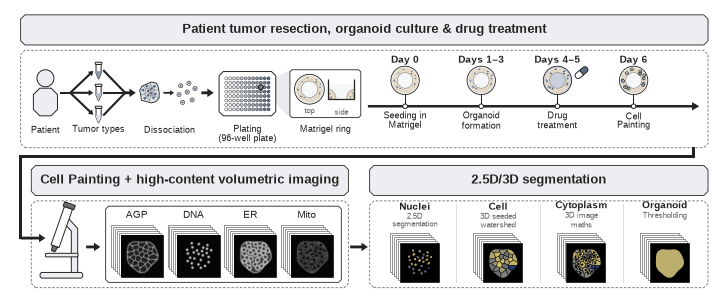

In [13]:
fig = build_figure()
plt.show()

## Export
Vector PDF and SVG keep text editable (Illustrator / Inkscape); the PNG is 600 dpi.

In [14]:
for ext, kw in [("png", {"dpi": 600})]:
    fig.savefig(f"{output_figure_file_path}.{ext}", facecolor="white", **kw)